# Tutorial for Pre-Processing Single-Cell Datasets

**Author:** Wei Yang  
**Region:** CN Region (snRNA-seq QC)  
**Date Last Modified:** October 8, 2023  

---

### Dataset Summary
* **Input:** Unfiltered `.h5ad` file from BAT-Lab pipelines for sci-RNA-seq3
* **Output:** Filtered `.h5ad` file annotated with cell class and cell subcluster labels

---

### Pipeline Workflow & Quality Control

1. **Initial Quality Filtering**  
   Removed nuclei of low quality or ambient RNA based on the following criteria:
   * **UMI counts:** $< 100$
   * **Genes detected:** $\le 100$
   * **Mitochondrial reads:** $\ge 10\%$
   * **Intronic mapping percentage:** $\ge 20\%$

2. **Doublet Detection (Scrublet)**  
   Subjected the filtered matrix to doublet calling via `Scrublet v0.2.3` (RRID:SCR_018098). Putative doublets were defined as those with scores $> 0.2$.

3. **Cell Type Annotation**  
   Annotated matrix with cell class and cell subtype labels using `TACCO`.

4. **Normalization & Cluster-Based Doublet Removal**  
   Log-normalized the matrix, applied dimensionality reduction, and partitioned via Louvain clustering (`resolution = 6`). Excluded clusters with $> 40\%$ predicted doublets (threshold determined by bimodal distribution).

5. **Outlier Filtering**  
   Excluded remaining low-quality or doublet nuclei with UMI counts $\le \text{mean} - 1\text{ SD}$ or $\ge \text{mean} + 2\text{ SD}$.

6. **Final Processing & Visualization**  
   Re-performed normalization and dimensionality reduction. Visualized final filtered dataset using UMAP (`min_dist = 0.25`, `spread = 1.0`, `n_components = 2`).

In [2]:
import bioalpha
import scanpy as sc
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
import math
import pandas as pd
import sys
import platform
import subprocess
from time import perf_counter as pc
import statistics
import re

In [3]:
print(f"Python Version: {platform.python_version()}")
print(f"Python Executable: {sys.executable}\n")
print("--- Installed Packages ---")

# Runs pip list using the active kernel's Python executable
result = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True)
print(result.stdout)

Python Version: 3.11.10
Python Executable: /packages/envs/bioalpha-0.13.0-cuda-12/bin/python

--- Installed Packages ---
Package                   Version
------------------------- -----------
anndata                   0.9.2
asttokens                 2.4.1
attrs                     24.2.0
bioalpha-cu12             0.13.1
certifi                   2024.8.30
charset-normalizer        3.4.0
comm                      0.2.2
contourpy                 1.3.0
ctxcore                   0.2.0
cycler                    0.12.1
cytoolz                   1.0.0
debugpy                   1.8.7
decorator                 5.1.1
exceptiongroup            1.2.2
executing                 2.1.0
fastjsonschema            2.20.0
fonttools                 4.54.1
frozendict                2.4.6
GEOparse                  2.0.4
gseapy                    1.1.3
h5py                      3.12.1
idna                      3.10
importlib_metadata        8.5.0
ipykernel                 6.29.5
ipython                   8.2

In [6]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
exec(open('/scratch/wyang114/bin/_figure_options.py').read())

In [7]:
np.random.seed(2023)
region = 'cn'  #specify region of interest

## Preprocessing

In [4]:
#open files for region of interest (in kenny's directory after de-multiplexing)
data_dir = f'/scratch/klchiou/bican/hdf5/raw_original/anndata_rna_{region}-all.h5ad'
adata = sc.read_h5ad(data_dir)

In [6]:
adata_raw = adata.shape[0]
np.median(adata.obs['n_umi'])

1660.0

In [7]:
df = adata.obs
df_sample = df.groupby('sample_id').size()
adata.obs['total_cell']=adata.obs['sample_id'].map(df_sample)

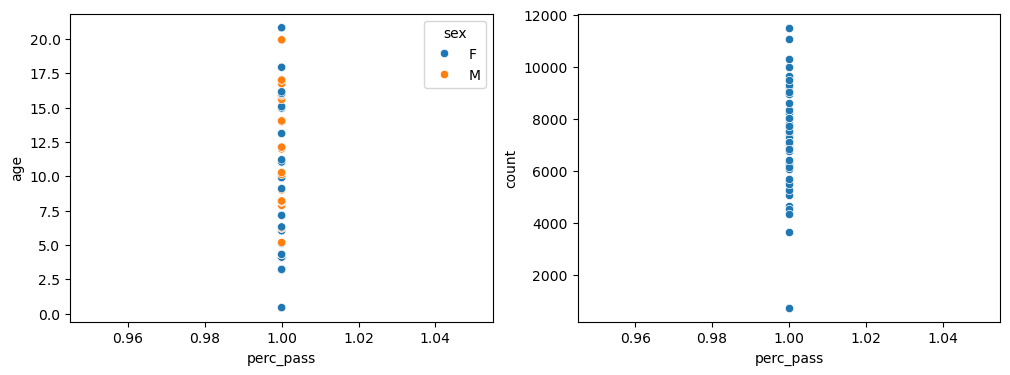

In [8]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_original.csv')

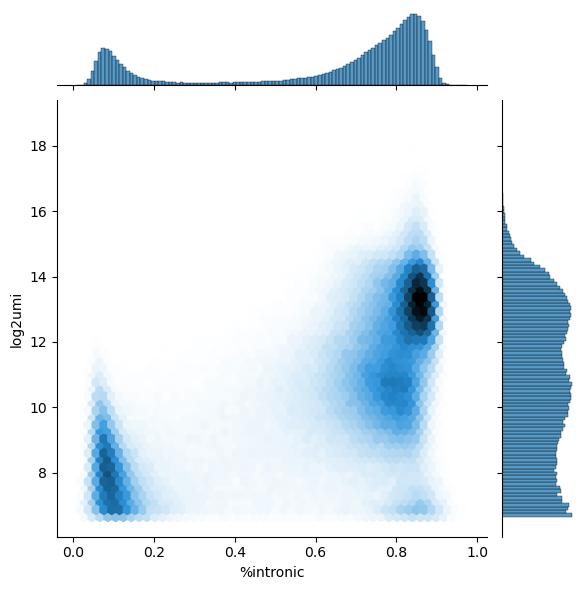

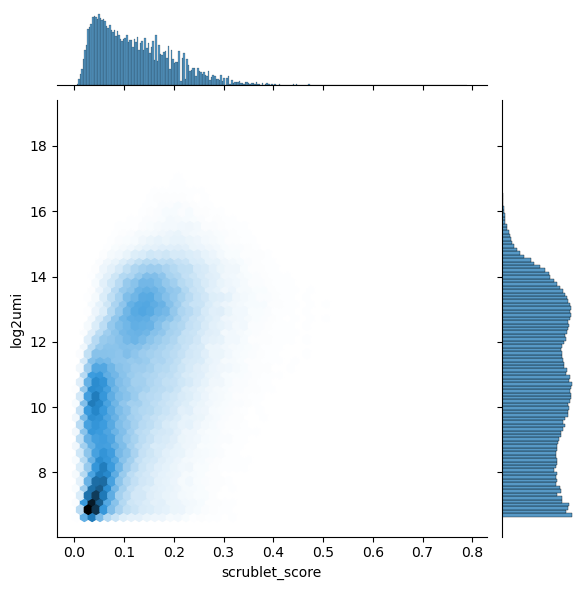

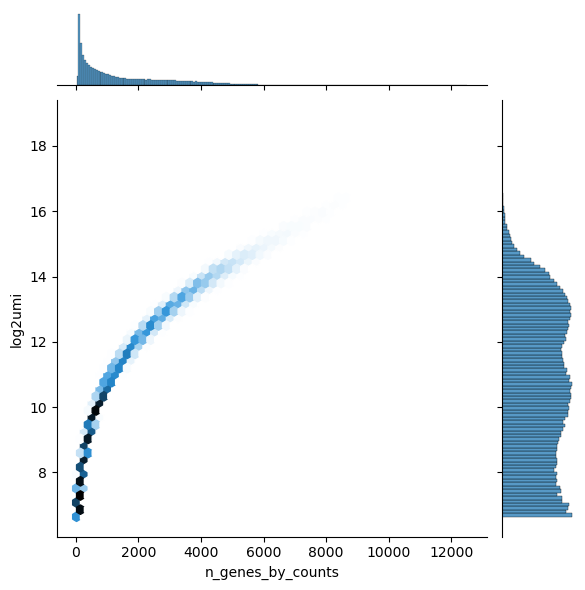

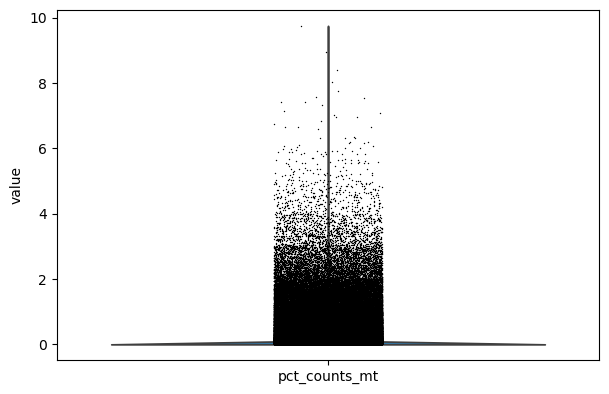

In [9]:
#Check mt%, %intronic, scurblet score and log2umi distribution for the raw dataset
adata.var['mt'] = adata.var['chr'] == 'MT'
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
adata.obs['%intronic']=adata.obs['n_intronic_umi']/adata.obs['n_umi']
adata.obs['log2umi']=[math.log2(i) for i in adata.obs['n_umi']]
#Visualize distributions
df=adata.obs
sns.jointplot(data=df,y='log2umi',x='%intronic',kind='hex')
sns.jointplot(data=df,y='log2umi',x='scrublet_score',kind='hex')
sns.jointplot(data=df,y='log2umi',x='n_genes_by_counts',kind='hex')
sc.pl.violin(adata, ['pct_counts_mt'],jitter=0.1)                    

In [10]:
#Filter out cells with low gene counts
gene_thre = 100
low_feature =sum(adata.obs['n_genes_by_counts']<= gene_thre)  #filter cells called as doublet by scrublet
print(f'filter out {low_feature}({low_feature/adata_raw*100}%) cells with low gene counts.')
adata = adata[adata.obs['n_genes_by_counts']> gene_thre,] 
del low_feature

filter out 13599(3.567914741556407%) cells with low gene counts.


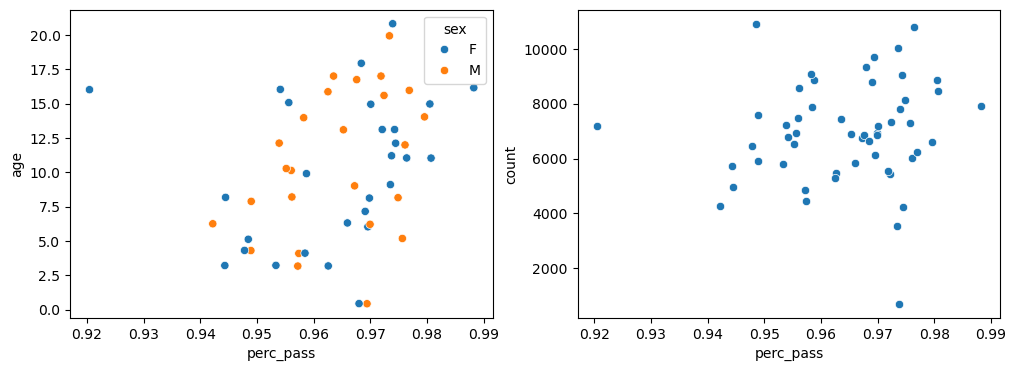

In [11]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_gene_filtered.csv')

In [12]:
#Filter out cells with high %mitochondrial reads
mito_thre = 10
dead_cell=sum(adata.obs['pct_counts_mt']>=mito_thre)  #filter cells called as doublet by scrublet
print(f'filter out {dead_cell}({dead_cell/adata_raw*100}%) potential dead cells.')
adata = adata[adata.obs['pct_counts_mt']<mito_thre,] 
del dead_cell

filter out 0(0.0%) potential dead cells.


In [13]:
#Filter out cells with low %intronic reads
intronic_thre = 0.2  #set threshold to filter low %intronic cells
intronic_cell=sum(adata.obs['%intronic']<=intronic_thre)
print(f'filter out {intronic_cell}({intronic_cell/adata_raw*100}%) low %intronic cells.')
adata = adata[adata.obs['%intronic']>intronic_thre,] 
del intronic_cell

filter out 63173(16.574445030395097%) low %intronic cells.


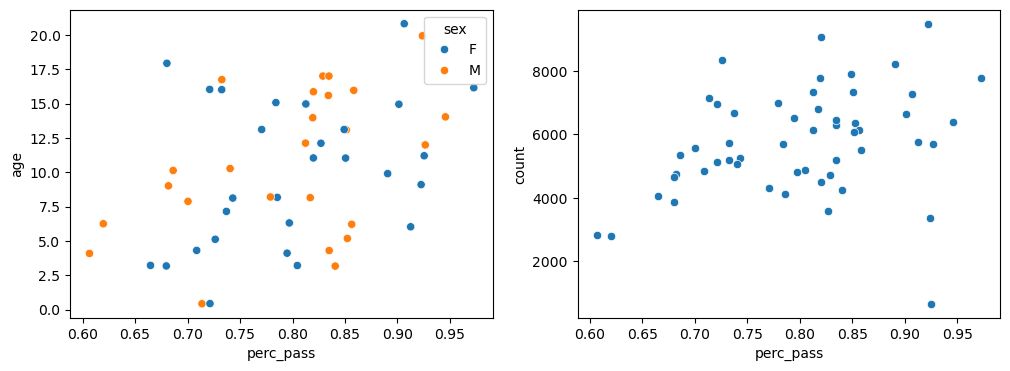

In [14]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_intronic_filtered.csv')

In [22]:
#Load filtered data from Kenny's scrublet output
adata = sc.read_h5ad(f'/scratch/klchiou/bican/hdf5/raw_filtered/anndata_rna_{region}-all.h5ad')
adata.raw = adata

In [23]:
adata

AnnData object with n_obs × n_vars = 304375 × 29060
    obs: 'sample_id', 'region', 'hemisphere', 'brain_id', 'necropsy_id', 'animal_id', 'sex', 'age', 'social_group', 'sci_library_run_id', 'sequencing_run_id', 'n_umi', 'n_intronic_umi', 'perc_mitochondrial_umis', 'bbi_scrublet_score', 'bbi_scrublet_call', 'scrublet_score', 'scrublet_call', 'sample_reads', 'sample_umi', 'sample_dup_rate', 'sample_doublet_count', 'sample_doublet_perc', 'sample_doublet_nas', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score_from_filtered', 'scrublet_call_from_filtered', 'total_cell'
    var: 'ensembl_gene_id', 'external_gene_name', 'chr', 'bp1', 'bp2', 'strand', 'mt'

In [24]:
#Doublet removal: cluster cells at high resolution
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[:,select_genes].copy()
adata.layers['raw'] = adata.X
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.louvain(adata, resolution=6)
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2)

Filtering out 51811 doublets 13.593442949833005%.


/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


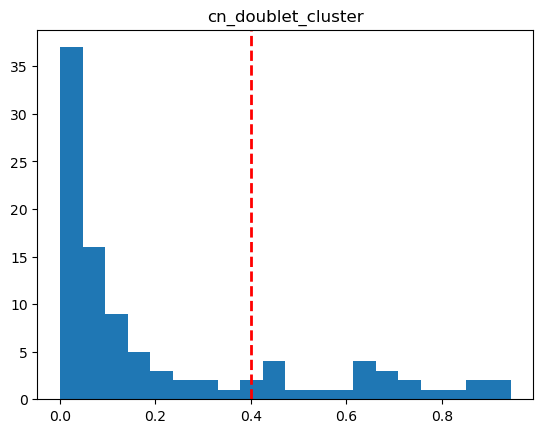

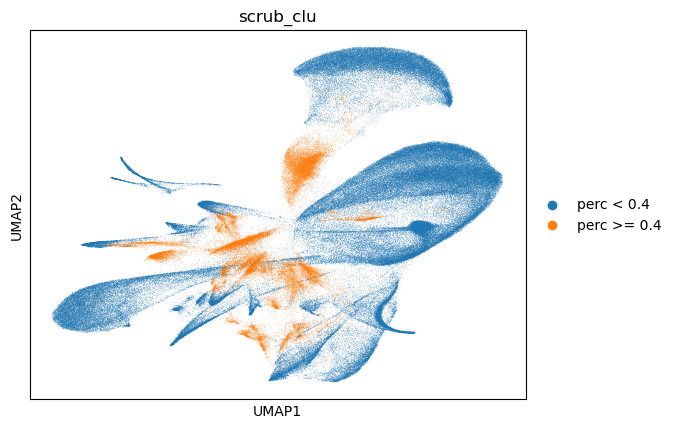

In [25]:
#Doublet removal: filter out clusters with percentage of doublet score > 0.2
df=adata.obs
thre = 0.4
def calculate_doublet_perc(s,thre):
    return (s>thre).mean()
select_clu = df.groupby('louvain')['scrublet_score_from_filtered'].apply(calculate_doublet_perc,thre=0.2)
plt.hist(select_clu,bins=20);
plt.title(f'{region}_doublet_cluster')
plt.axvline(x=thre, color='red', linestyle='dashed', linewidth=2)
select_cells = np.where(df['louvain'].isin(select_clu[select_clu<thre].index)) 
adata.obs['scrub_clu'] = f'perc >= {thre}'
adata.obs.loc[adata.obs.index[select_cells],'scrub_clu']= f'perc < {thre}'
doublets = sum(adata.obs['scrub_clu']==f'perc >= {thre}')
print(f'Filtering out {doublets} doublets {doublets/adata_raw*100}%.')
sc.pl.umap(adata,color='scrub_clu')
adata = adata[adata.obs['scrub_clu']==f'perc < {thre}']

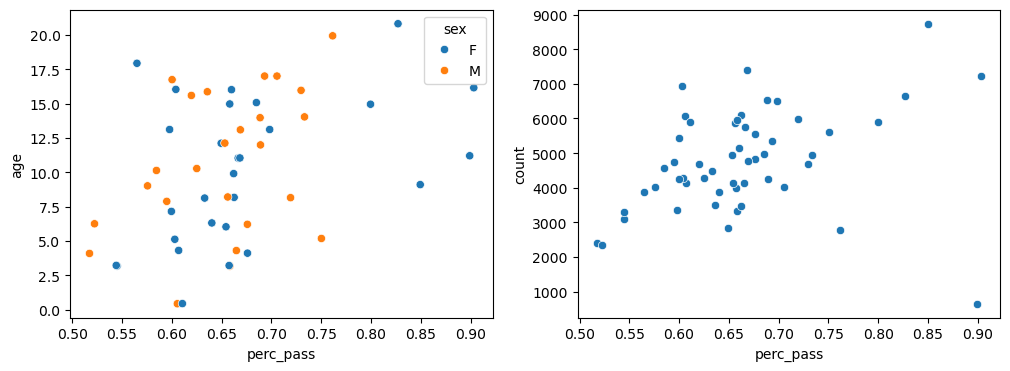

In [26]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_doublet_filtered.csv')

In [27]:
#save intermediate file for tacco cell class annotation
adata.write_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)

##### Note: Use Run_tacco.py to annotate cell class and subcluster and then use the output for subsequent steps
##### 1. module load mamba/latest
##### 2. source activate TACCO_env
##### 3. open ./Run_tacco_v2.py and change the region param to capitalized region name
##### 4. python ./Run_tacco_v2.py

In [ ]:
#Open adata file after tacco cell class annotation and add franken
import anndata as ad
adata = sc.read_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)
franken = sc.read_h5ad("/scratch/wyang114/processed_data/anndata_rna_franken_cn_processed_Feb.h5ad")
adata = adata.raw.to_adata()
adata.raw = adata
franken = franken.raw.to_adata()
franken.raw=franken
adata_raw = ad.concat([adata,franken],keys=['ori','fran'],index_unique='_',merge='same')
adata_raw.raw = adata_raw
adata = adata_raw
adata.obs['%intronic']=adata.obs['n_intronic_umi']/adata.obs['n_umi']
adata.obs['log2umi']=[math.log2(i) for i in adata.obs['n_umi']]

NameError: name 'sc' is not defined

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


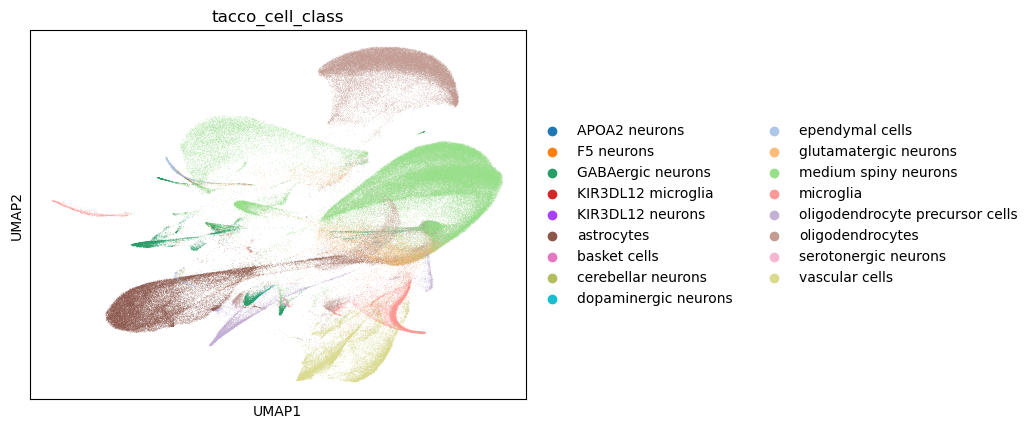

In [5]:
sc.pl.umap(adata, color='tacco_cell_class')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


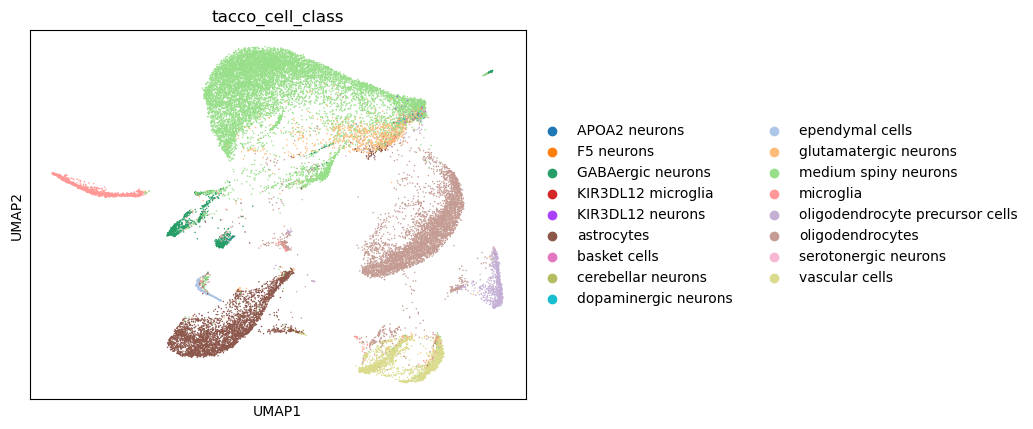

In [5]:
sc.pl.umap(franken, color='tacco_cell_class')

Non-Neuron threshold: 8.83 12.85; Neuron threshold: 9.53 16.05


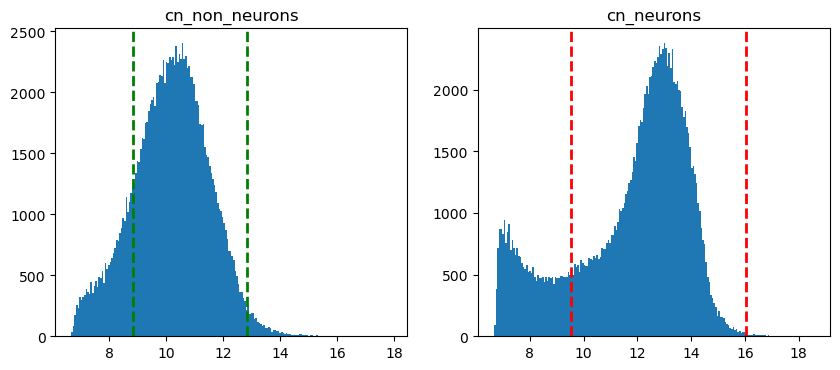

In [6]:
#filter low and high umi cells with neurons and non-neurons
neurons = ['cerebellar neurons','dopaminergic neurons','GABAergic neurons', 'glutamatergic neurons',
           'F5 neurons','APOA2 neurons','KIR3DL12 neurons','medium spiny neurons','basket cells',
          'serotonergic neurons']
non_neurons = ['astrocytes','ependymal cells','microglia','oligodendrocyte precursor cells',
               'oligodendrocytes','vascular cells','KIR3DL12 microglia']

#Calculating threshold
df_non_neurons = adata.obs[adata.obs['tacco_cell_class'].isin(non_neurons)]
df_neurons = adata.obs[adata.obs['tacco_cell_class'].isin(neurons)]
#neruon threshold
a1 = statistics.mean(df_non_neurons['log2umi'])-statistics.stdev(df_non_neurons['log2umi'])
a2 = statistics.mean(df_non_neurons['log2umi'])+2*statistics.stdev(df_non_neurons['log2umi'])
#non-neruon threshold
b1 = statistics.mean(df_neurons['log2umi'])-statistics.stdev(df_neurons['log2umi'])
b2 = statistics.mean(df_neurons['log2umi'])+2*statistics.stdev(df_neurons['log2umi'])
print('Non-Neuron threshold: %.2f %.2f; Neuron threshold: %.2f %.2f'%(a1,a2,b1,b2))

#plotting
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax[0].hist(df_non_neurons['log2umi'],bins=200);
ax[0].axvline(x=a1, color='green', linestyle='dashed', linewidth=2)
ax[0].axvline(x=a2, color='green', linestyle='dashed', linewidth=2)
ax[0].set_title(f'{region}_non_neurons')

ax[1].hist(df_neurons['log2umi'],bins=200,);
ax[1].axvline(x=b1, color='red', linestyle='dashed', linewidth=2)
ax[1].axvline(x=b2, color='red', linestyle='dashed', linewidth=2)
ax[1].set_title(f'{region}_neurons')
plt.savefig(f'/scratch/wyang114/figures/qc/{region}_neurons_non_neurons_umi.pdf')

In [7]:
select_non_neurons = df_non_neurons.index[(df_non_neurons['log2umi']>a1) & (df_non_neurons['log2umi']<a2)]
select_neurons = df_neurons.index[(df_neurons['log2umi']>b1) & (df_neurons['log2umi']<b2)]
select_cells = select_neurons.union(select_non_neurons)
umi_cells = adata.shape[0]-len(select_cells)
#print(f'filter out {umi_cells}({umi_cells/adata_raw*100}%) low and high umi cells.')
adata = adata[select_cells] 
del umi_cells

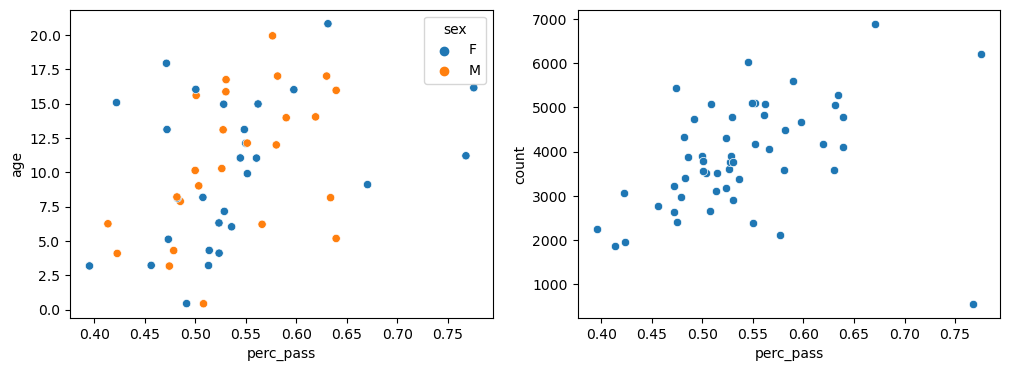

In [15]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_umi_filtered.csv')

## Re-clustering with final set of cells

In [8]:
#Start from raw data again and re-do dimensional reduction and clustering with the filtered cells
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[:,select_genes].copy()
adata.layers['raw'] = adata.X
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
sc.pp.regress_out(adata, keys='n_umi',n_jobs =20)
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.louvain(adata, resolution=6)
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


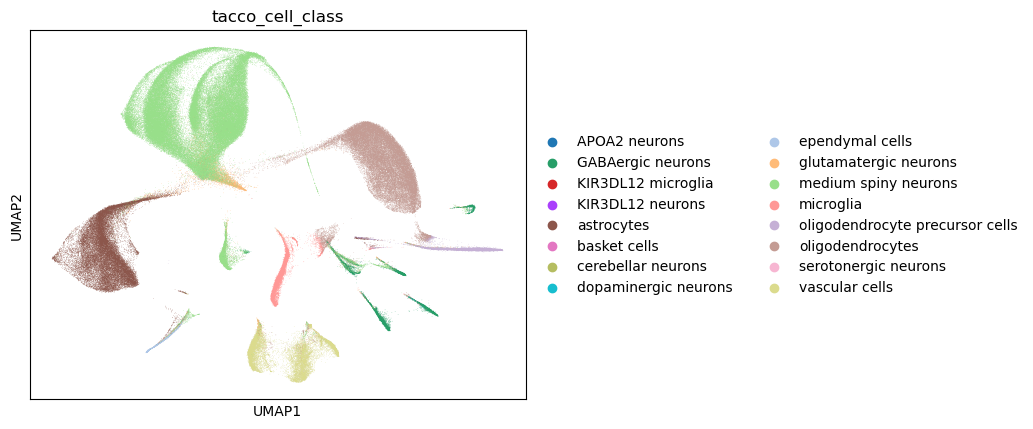

In [10]:
sc.pl.umap(adata,color='tacco_cell_class')

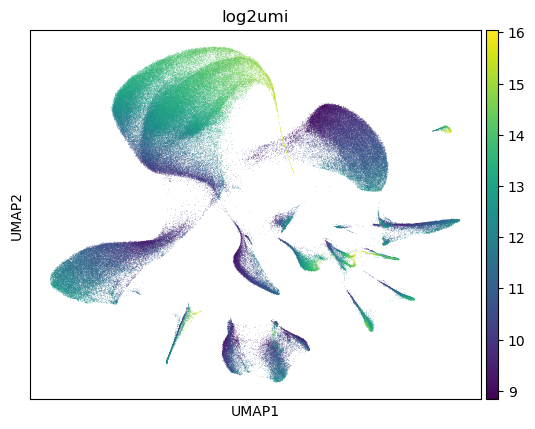

In [70]:
sc.pl.umap(adata,color='log2umi')

## Transfer label

In [45]:
######Prepare metadata for louvain clusters
df = adata.obs.groupby('louvain')['tacco_cell_class'].value_counts(normalize=True).unstack()
first_cc = pd.concat([df.idxmax(axis=1),df.max(axis=1)],axis=1)
first_cc.columns = ['first_cc','first_cc_score']
first_cc['1st/2nd identity(cc)']=df.apply(lambda row: row.nlargest(2).values[0]/(row.nlargest(2).values[1]+0.001), axis=1)

df = adata.obs.groupby('louvain')['tacco_cell_subcluster'].value_counts(normalize=True).unstack()
first_sc = pd.concat([df.idxmax(axis=1),df.max(axis=1)],axis=1)
first_sc.columns = ['first_sc','first_sc_score']
temp_1 = adata.obs.groupby('louvain')['scrublet_score_from_filtered'].mean()
temp_2 = adata.obs.groupby('louvain')['tacco_cell_class_score'].mean()
temp_3 = adata.obs.groupby('louvain')['tacco_cell_subcluster_score'].mean()
first_sc['1st/2nd identity(sc)'] = df.apply(lambda row: row.nlargest(2).values[0]/(row.nlargest(2).values[1]+0.001), axis=1)

df_all = pd.concat([first_cc,temp_2,first_sc,temp_3,temp_1],axis=1)
df_all['sc_cc_match']=[re.findall(df_all.loc[x,'first_cc'],df_all.loc[x,'first_sc'])!=[] for x in df_all.index]

(0.0, 1.05)

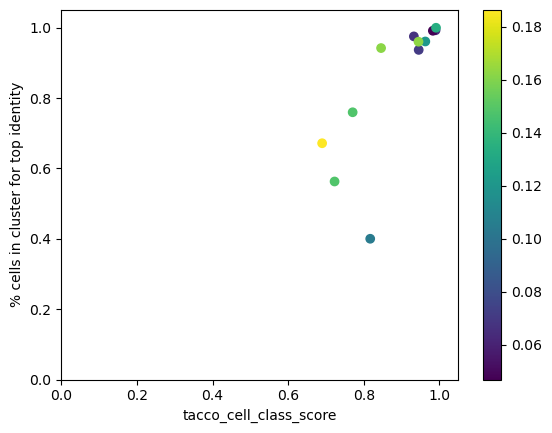

In [38]:
#Plot the distribution of tacco score vs specificity colored by doublet score
x = np.array(df_all['tacco_cell_class_score'])
y = np.array(df_all['first_cc_score'])
color = np.array(df_all['scrublet_score_from_filtered'])
plt.scatter(x,y,c=color, cmap='viridis')
plt.xlabel('tacco_cell_class_score')
plt.ylabel('% cells in cluster for top identity')
plt.colorbar()
plt.xlim(0,1.05)
plt.ylim(0,1.05)

(0.0, 1.05)

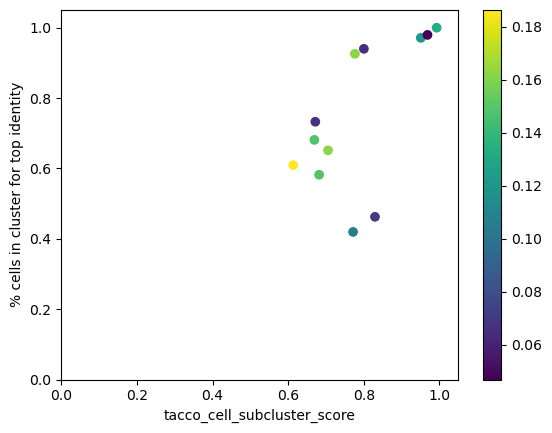

In [39]:
#Plot the distribution of tacco score vs specificity colored by doublet score
x = np.array(df_all['tacco_cell_subcluster_score'])
y = np.array(df_all['first_sc_score'])
color = np.array(df_all['scrublet_score_from_filtered'])
plt.scatter(x,y,c=color, cmap='viridis')
plt.xlabel('tacco_cell_subcluster_score')
plt.ylabel('% cells in cluster for top identity')
plt.colorbar()
plt.xlim(0,1.05)
plt.ylim(0,1.05)

In [46]:
######Transfer annotation
#simple version (majority ruling)
df_all['cell_class_assignment']=np.nan
df_all['cell_subcluster_assignment']=np.nan

#Majority ruling of cell class if the top identity is >3x than the 2nd identity.
thre = 0.7
df_all.loc[df_all['first_cc_score']>=thre,'cell_class_assignment'] = df_all.loc[df_all['first_cc_score']>=thre,'first_cc']
df_all.loc[df_all['1st/2nd identity(cc)']>=3,'cell_class_assignment'] = df_all.loc[df_all['1st/2nd identity(cc)']>=3,'first_cc']  
#label everything else as unknown with top ident information
remain_cells = df_all['cell_class_assignment'].isna()
unknown = df_all.loc[remain_cells,]
unknown['cell_class_assignment'] = ['_'.join(['unknown',unknown['first_cc'][i],
                                           region+unknown.index[i]]) for i in range(unknown.shape[0])]
df_all.loc[unknown.index,'cell_class_assignment'] = unknown['cell_class_assignment']

#Majority ruling of cell subcluster if the top identity is >3x than the 2nd identity 
#Clusters with unmatched cell class and subcluster and everthing not satisfied the previous will be labled as unknown
df_all.loc[df_all['first_sc_score']>=thre,'cell_subcluster_assignment'] = df_all.loc[df_all['first_sc_score']>=thre,'first_sc']
df_all.loc[df_all['1st/2nd identity(sc)']>=3,'cell_subcluster_assignment'] = df_all.loc[df_all['1st/2nd identity(sc)']>=3,'first_sc']
df_all.loc[df_all['sc_cc_match']==False,'cell_subcluster_assignment'] = np.nan  
#label everything else as unknown with top ident information
remain_cells = df_all['cell_subcluster_assignment'].isna()
unknown = df_all.loc[remain_cells,]
unknown['cell_subcluster_assignment'] = ['_'.join(['unknown',unknown['first_sc'][i],
                                           region+unknown.index[i]]) for i in range(unknown.shape[0])]
df_all.loc[unknown.index,'cell_subcluster_assignment'] = unknown['cell_subcluster_assignment']

adata.obs['cell_class_assign'] = adata.obs['louvain'].map(df_all['cell_class_assignment'])
adata.obs['cell_subcluster_assign'] = adata.obs['louvain'].map(df_all['cell_subcluster_assignment'])

/tmp/ipykernel_578580/2306629916.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unknown['cell_class_assignment'] = ['_'.join(['unknown',unknown['first_cc'][i],
/tmp/ipykernel_578580/2306629916.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unknown['cell_subcluster_assignment'] = ['_'.join(['unknown',unknown['first_sc'][i],


In [7]:
adata.obs['sequencing_run_id'].value_counts()

sequencing_run_id
Snyder-Mackler_RNA3-058_059_nova_data           206500
Snyder-Mackler_RNA3-059_franken_novaseq_data     21362
Name: count, dtype: int64

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


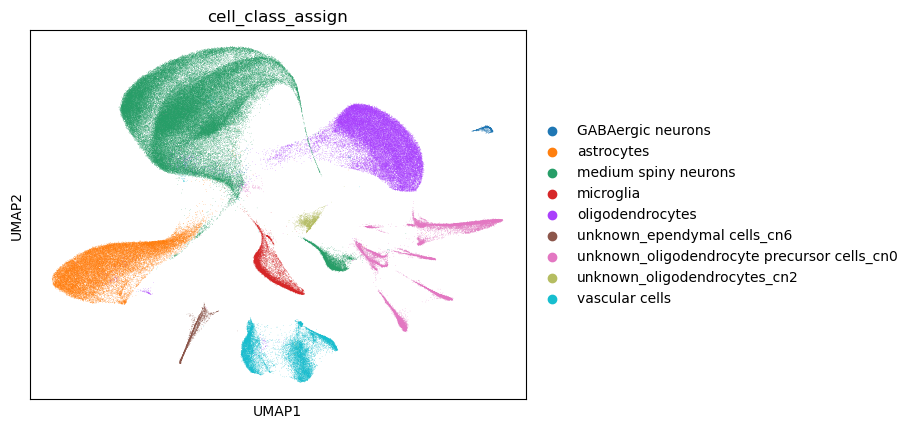

In [47]:
sc.pl.umap(adata,color='cell_class_assign')
#unknown_grp = [cat for cat in adata.obs['cell_class_assign'].cat.categories if re.search('unknown',cat)]
#sc.pl.umap(adata,color='cell_class_assign',groups=unknown_grp,size=3)

In [23]:
adata = sc.read_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_cn_filtered_wfrank.h5ad")

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


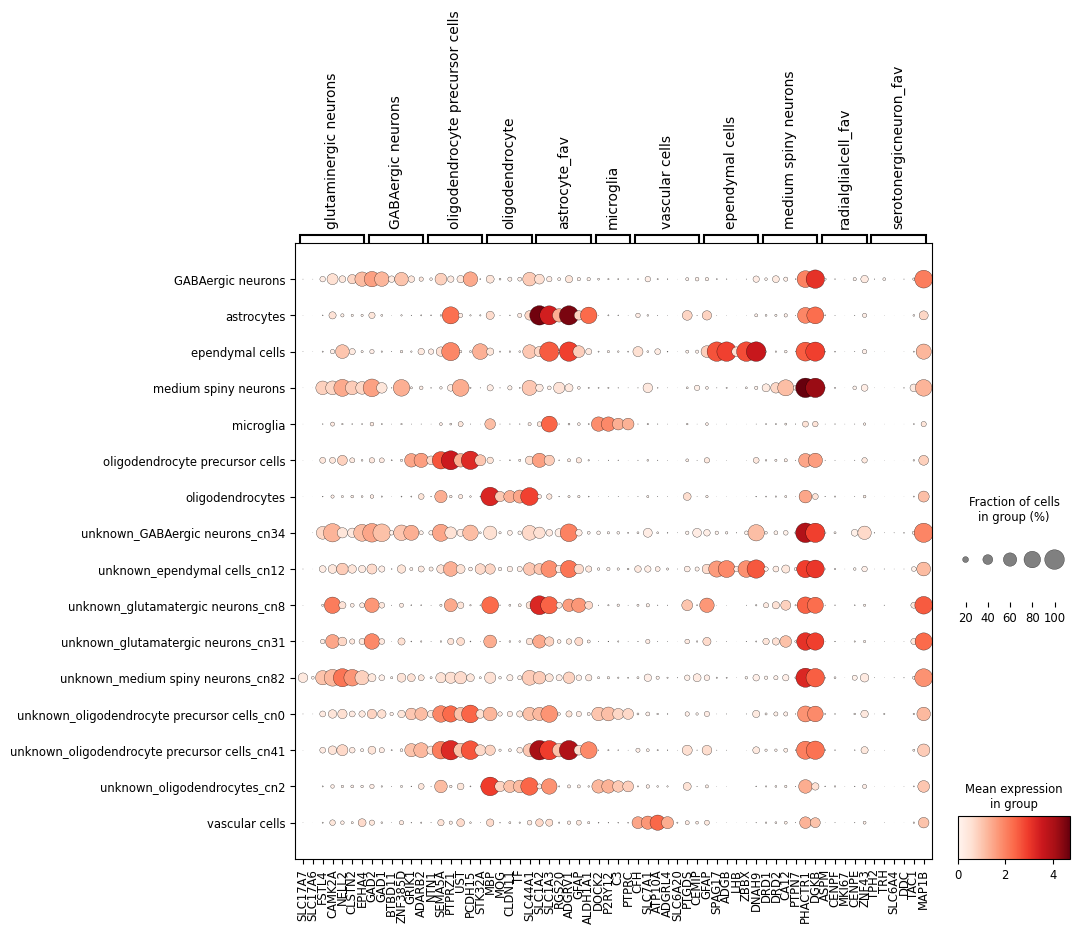

In [10]:
adata=adata.raw.to_adata()
adata.raw = adata 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
marker_genes_dict = {'glutaminergic neurons': ['SLC17A7','SLC17A6','FSTL4','CAMK2A','NELL2','CLSTN2','EPHA4'],
                     'GABAergic neurons': ['GAD2','GAD1','BTBD11','ZNF385D','GRIK1','ADARB2'],
                     'oligodendrocyte precursor cells': ['NTN1','SEMA5A','PTPRZ1','UST','PCDH15','STK32A'],
                     'oligodendrocyte': ['MBP','MOG','CLDN11','TF','SLC44A1'],
                     'astrocyte_fav': ['SLC1A2','SLC1A3','RGS20','ADGRV1','GFAP','ALDH1A1'],
                     'microglia':['DOCK2','P2RY12','C3','PTPRC'],
                     'vascular cells':['CFH','SLC7A1','ATP10A','ADGRL4','SLC6A20','PTGDS','CEMIP'],
                     'ependymal cells':['GFAP','SPAG17','ADGB','LHB','ZBBX','DNAH9'],
                     'medium spiny neurons':['DRD1','DRD2','CA12','PTPN7','PHACTR1','DGKB'],
                    'radialglialcell_fav': ['ASPM','CENPF','MKI67','CENPE','ZNF43'],
                    'serotonergicneuron_fav': ['TPH2','TRH','SLC6A4','DDC','TAC1','MAP1B'],
                    }
ax = sc.pl.dotplot(adata, marker_genes_dict, groupby='cell_class_assign',gene_symbols='external_gene_name',
                      figsize=[10,8],use_raw=False)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


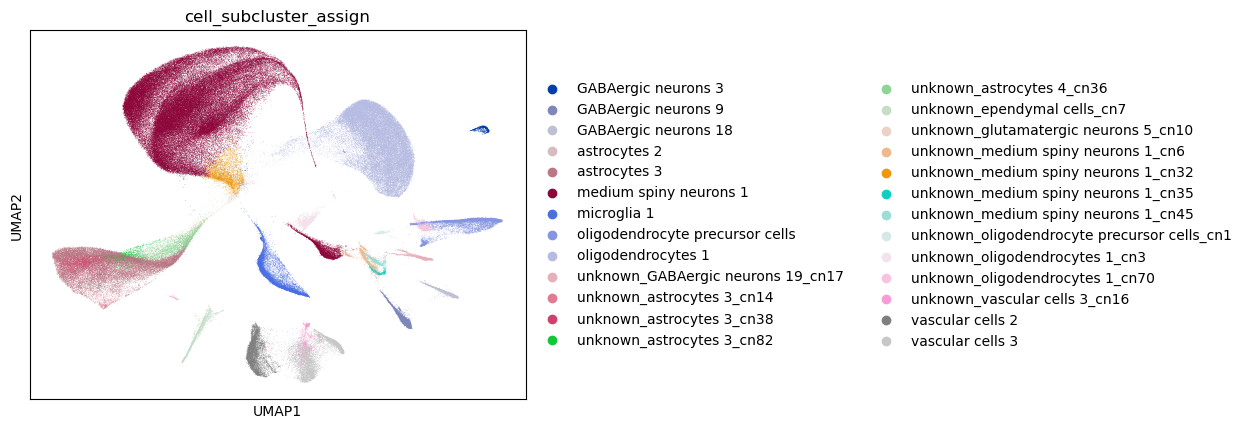

In [18]:
sc.pl.umap(adata,color='log2umi')

In [8]:
#adata.write_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_%s_filtered_wfrank.h5ad"%region)
adata = sc.read_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_%s_filtered_wfrank.h5ad"%region)

In [18]:
# exec(open('/scratch/wyang114/bin/_figure_options.py').read())
# plt_cell_class(adata)
# plt_cell_composition(adata)

In [24]:
#Export for scrattch
##import scipy.sparse
#adata = sc.read_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_%s_filtered_wfrank.h5ad"%region)
# adata = adata.raw.to_adata()
# scipy.sparse.save_npz('/scratch/wyang114/processed_data/filtered_data_Feb/cn_adata/count_matrix.npz',adata.X)
# adata.obs.to_csv('/scratch/wyang114/processed_data/filtered_data_Feb/cn_adata/obs.csv')
#bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
#bioalpha.sc.pp.log1p(adata)
#bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
#adata.var.to_csv('/scratch/wyang114/processed_data/filtered_data_Feb/cn_adata/var.csv')
#np.savez('/scratch/wyang114/processed_data/filtered_data_Feb/cn_adata/pca.npz',adata.obsm['X_pca'])

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


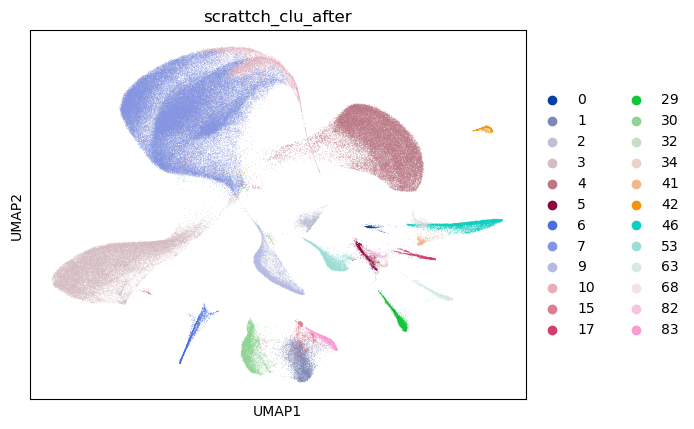

In [10]:
scrattch_merge = pd.read_csv('/scratch/wyang114/processed_data/filtered_data_Feb/cn_adata/scrattch_merge_coarse.csv',index_col=0)
adata.obs['scrattch_clu_after'] = [str(i) for i in scrattch_merge['scrattch_clu_after']]
sc.pl.umap(adata,color='scrattch_clu_after')

In [15]:
df_cluster = adata.obs.groupby(['louvain','cell_class_assign']).size().reset_index()
df_cluster.columns = ['louvain','cell_class_assign','count']
df_cluster = df_cluster[df_cluster['count']>0]
df_cluster.index = df_cluster['louvain']
adata.obs['cell_class_assign']=adata.obs['scrattch_clu_after'].map(df_cluster['cell_class_assign'])
adata.obs['cell_class_assign']=adata.obs['cell_class_assign'].astype('str')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


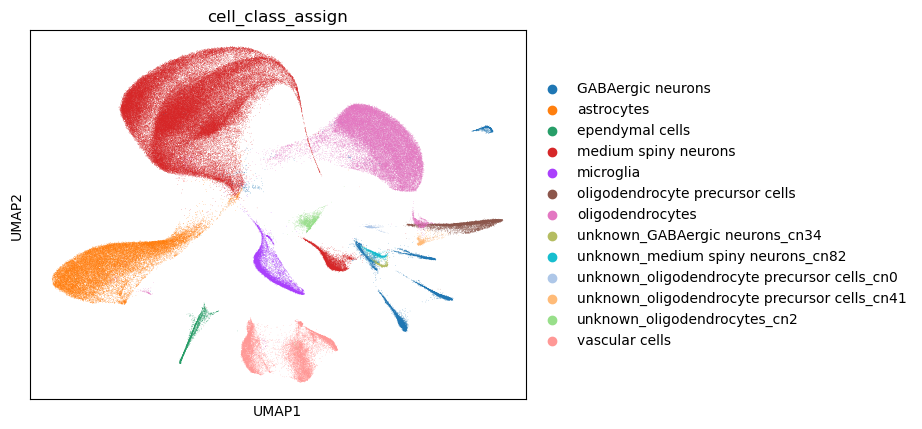

In [21]:
sc.pl.umap(adata,color='cell_class_assign','tab20')

In [25]:
adata.obs['RT_well']=[adata.obs.index[i].split('_')[3] for i in range(len(adata.obs.index))]
adata.obs['P5_well']=[adata.obs.index[i].split('_')[1] for i in range(len(adata.obs.index))]
df = adata.obs.groupby(['RT_well','P5_well']).size().unstack().fillna(0)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


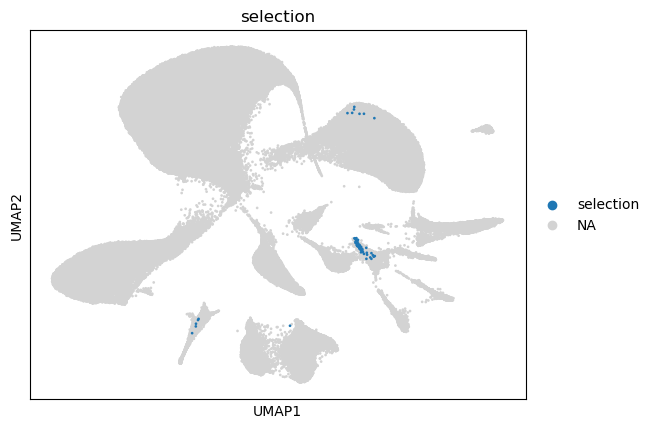

In [40]:
select_index = adata[~adata.obs['P5_well'].isin(['A01','B01','C01','D01'])].obs_names
adata.obs['selection'] = np.nan
adata.obs.loc[select_index,'selection']='selection'
sc.pl.umap(adata,color = 'selection',size=15)

In [24]:
adata.write_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_%s_filtered_wfrank.h5ad"%region)

## Subclustering

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


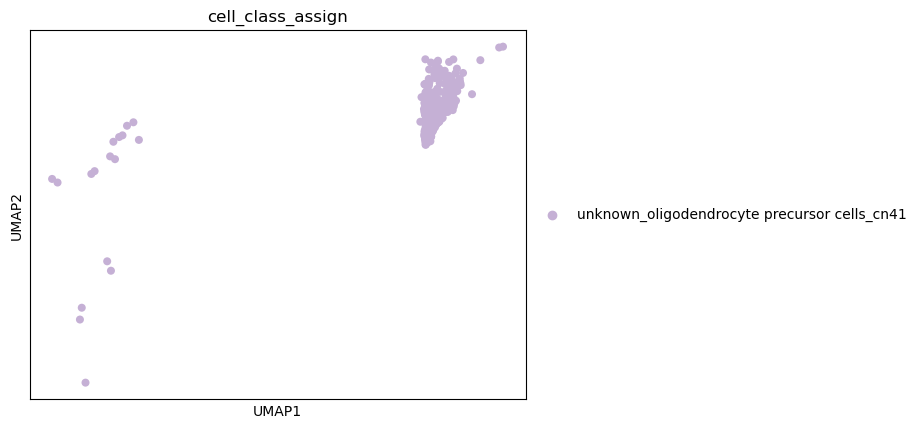

In [19]:
#Start from the raw data with all the genes
adata_all = sc.read_h5ad("/scratch/wyang114/processed_data/filtered_data_Feb/anndata_rna_%s_filtered_wfrank.h5ad"%region)
cell_class = 'unknown_oligodendrocyte precursor cells_cn41'   #Choose the cell class here
cell_class_obs = adata_all.obs[adata_all.obs['cell_class_assign']==cell_class]
cell_class_index = cell_class_obs.index
sc.pl.umap(adata_all[cell_class_index],color='cell_class_assign')

In [20]:
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
subset = adata[cell_class_index,select_genes].copy()
subset = subset.raw.to_adata()
subset.raw=subset
subset.layers['raw'] = subset.X
print(subset.shape)
bioalpha.sc.pp.normalize_total(subset, target_sum=1e4)
bioalpha.sc.pp.log1p(subset)
bioalpha.sc.pp.highly_variable_genes(subset, n_top_genes=2000)
subset = subset[:, subset.var.highly_variable]
subset.layers['normalized_unscaled'] = subset.X
sc.pp.regress_out(subset, keys='n_umi',n_jobs=20)  #optional
bioalpha.sc.pp.scale(subset, max_value=10)
bioalpha.sc.tl.pca(subset, n_comps=50)
bioalpha.sc.pp.neighbors(subset, n_neighbors=30, n_pcs=30) #n_neighbors=30, n_pcs=30
bioalpha.sc.tl.umap(subset,min_dist=0.25,spread=1.0, n_components=2) #min_dist=0.25,spread=1.0

(901, 29060)


/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


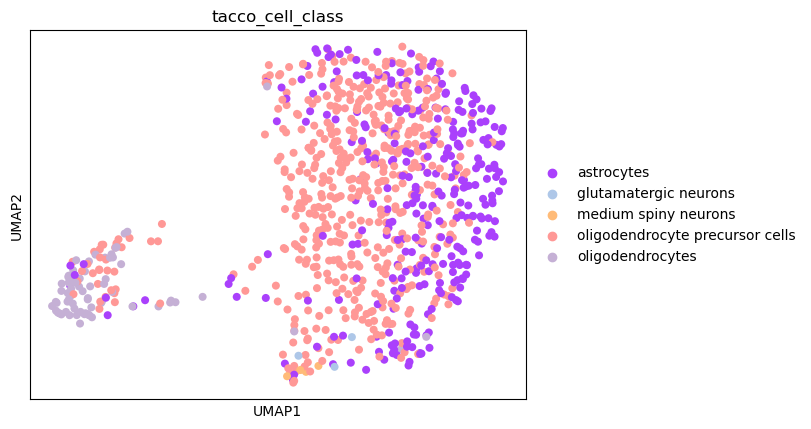

In [21]:
sc.pl.umap(subset,color='tacco_cell_class')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


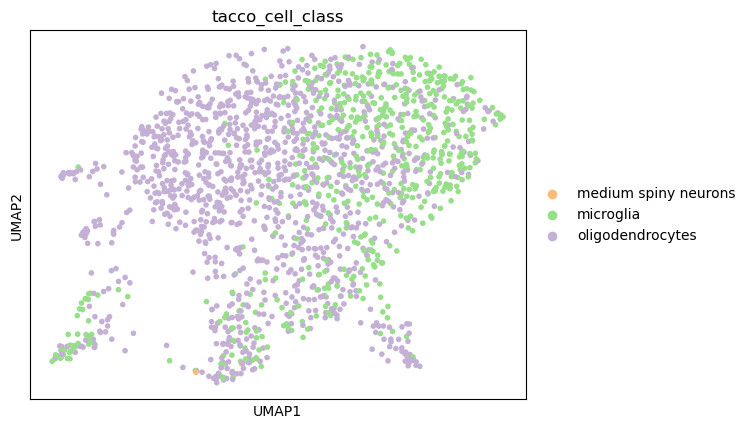

In [17]:
sc.tl.louvain(subset)
sc.pl.umap(subset,color='tacco_cell_class')

In [ ]:
#Transfer meta data information to the sub-clustering data
print(sum(adata.obs.index == cell_class_obs.index)/adata.shape[0])
adata.obs['cell_class_assign'] = cell_class_obs['cell_class_assign'].astype('str')
adata.obs['cell_subcluster_assign'] = cell_class_obs['cell_subcluster_assign'].astype('str')
adata.obs['log2umi'] = cell_class_obs['log2umi']
adata.obs['lv1_louvain_6'] = cell_class_obs['louvain'].astype('str')

In [ ]:
sns.set(rc={"figure.figsize":(5, 5)})
sns.set(style='white')
sc.pl.umap(adata,color='cell_subcluster_assign')

In [ ]:
sns.set(rc={"figure.figsize":(5, 5)})
sns.set(style='white')
sc.pl.umap(adata,color='lv1_louvain_6')